In [1]:
%pip install -U scikit-learn nltk

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 11.2 MB/s  0:00:00

  Attempting uninstall: scikit-learn

    Found existing installation: scikit-learn 1.9.0

    Uninstalling scikit-learn-1.9.0:

      Successfully uninstalled scikit-learn-1.9.0

   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\AMIT\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
import os
import re
import shutil
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
documents = [
    ("The team won the football match and scored two goals.", "Sports"),
    ("The cricket player scored a century in the tournament.", "Sports"),
    ("The coach prepared the team for the championship.", "Sports"),
    ("The basketball team won the final game.", "Sports"),
    ("The tennis player won the grand slam match.", "Sports"),

    ("The government announced a new economic policy.", "Politics"),
    ("The election campaign started in the state.", "Politics"),
    ("The parliament discussed the new national law.", "Politics"),
    ("The minister addressed the public meeting.", "Politics"),
    ("The political party announced its election manifesto.", "Politics"),

    ("Artificial intelligence is transforming modern technology.", "Technology"),
    ("Machine learning models analyze large datasets.", "Technology"),
    ("Cybersecurity protects computers from online attacks.", "Technology"),
    ("Cloud computing provides scalable computing resources.", "Technology"),
    ("Software developers are building a new mobile application.", "Technology"),

    ("The doctor recommended exercise and a healthy diet.", "Health"),
    ("Regular physical activity improves overall fitness.", "Health"),
    ("The hospital introduced a new patient care system.", "Health"),
    ("A balanced diet provides essential nutrients.", "Health"),
    ("Researchers are studying treatments for the disease.", "Health")
]

df = pd.DataFrame(documents, columns=["text", "category"])

print("Dataset created successfully!")
print("Total documents:", len(df))
display(df.head())

Dataset created successfully!
Total documents: 20


,text,category
0,The team won the football match and scored two...,Sports
1,The cricket player scored a century in the tou...,Sports
2,The coach prepared the team for the championship.,Sports
3,The basketball team won the final game.,Sports
4,The tennis player won the grand slam match.,Sports


Category distribution:
category
Sports        5
Politics      5
Technology    5
Health        5
Name: count, dtype: int64


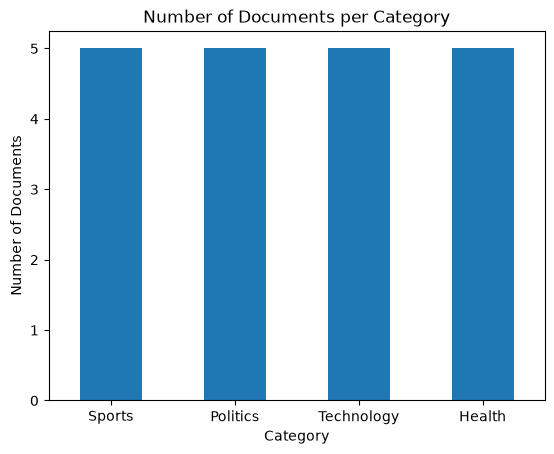

In [4]:
print("Category distribution:")
print(df["category"].value_counts())

df["category"].value_counts().plot(
    kind="bar",
    title="Number of Documents per Category",
    xlabel="Category",
    ylabel="Number of Documents",
    rot=0
);

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"],
    df["category"],
    test_size=0.25,
    random_state=42,
    stratify=df["category"]
)

print("Training documents:", len(X_train))
print("Testing documents:", len(X_test))

Training documents: 15
Testing documents: 5


In [6]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2)
    )),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)

print("Document classification model trained successfully!")

Document classification model trained successfully!


In [7]:
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
))

Accuracy: 40.0 %

Classification Report:
              precision    recall  f1-score   support

      Health       0.00      0.00      0.00         1
    Politics       0.33      1.00      0.50         1
      Sports       1.00      0.50      0.67         2
  Technology       0.00      0.00      0.00         1

    accuracy                           0.40         5
   macro avg       0.33      0.38      0.29         5
weighted avg       0.47      0.40      0.37         5

Confusion Matrix:
[[0 1 0 0]
 [0 1 0 0]
 [0 1 1 0]
 [1 0 0 0]]


In [8]:
new_documents = [
    "The football team won the tournament after a difficult match.",
    "Scientists developed a new artificial intelligence system.",
    "The government announced plans before the upcoming election.",
    "Doctors recommend a nutritious diet and regular exercise."
]

predictions = model.predict(new_documents)

for text, category in zip(new_documents, predictions):
    print("Document:", text)
    print("Predicted Category:", category)
    print("-" * 60)

Document: The football team won the tournament after a difficult match.
Predicted Category: Sports
------------------------------------------------------------
Document: Scientists developed a new artificial intelligence system.
Predicted Category: Technology
------------------------------------------------------------
Document: The government announced plans before the upcoming election.
Predicted Category: Politics
------------------------------------------------------------
Document: Doctors recommend a nutritious diet and regular exercise.
Predicted Category: Health
------------------------------------------------------------


In [9]:
output_dir = "classified_documents"

os.makedirs(output_dir, exist_ok=True)

for category in model.classes_:
    os.makedirs(os.path.join(output_dir, category), exist_ok=True)

for i, (text, category) in enumerate(
    zip(new_documents, predictions),
    start=1
):
    file_path = os.path.join(
        output_dir,
        category,
        f"document_{i}.txt"
    )

    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text)

print("Documents separated successfully!")

for category in model.classes_:
    folder = os.path.join(output_dir, category)
    print(f"{category}: {len(os.listdir(folder))} document(s)")

Documents separated successfully!
Health: 1 document(s)
Politics: 1 document(s)
Sports: 1 document(s)
Technology: 1 document(s)


In [10]:
user_text = input("Enter a document to classify: ").strip()

if user_text:
    predicted_category = model.predict([user_text])[0]

    print("\nPredicted Category:", predicted_category)

    save_choice = input("Save this document in its category folder? (yes/no): ")

    if save_choice.strip().lower() == "yes":
        folder = os.path.join(output_dir, predicted_category)
        os.makedirs(folder, exist_ok=True)

        existing_files = [
            f for f in os.listdir(folder)
            if f.startswith("user_document_") and f.endswith(".txt")
        ]

        file_path = os.path.join(
            folder,
            f"user_document_{len(existing_files) + 1}.txt"
        )

        with open(file_path, "w", encoding="utf-8") as file:
            file.write(user_text)

        print("Document saved to:", file_path)
else:
    print("Please enter a non-empty document.")

Enter a document to classify:  The doctor recommended exercise and a healthy diet



Predicted Category: Health


Save this document in its category folder? (yes/no):  yes


Document saved to: classified_documents\Health\user_document_1.txt


In [11]:
print("Experiment completed successfully.")
print("TF-IDF and Multinomial Naive Bayes were used for document classification.")
print("Documents were automatically classified and separated into category folders.")

Experiment completed successfully.
TF-IDF and Multinomial Naive Bayes were used for document classification.
Documents were automatically classified and separated into category folders.
